# Score-Based Generative Modeling through SDEs（Song et al., 2021）

这个 notebook 使用二维高斯混合分布，完整拆解论文中的连续时间生成框架。二维问题具有解析边缘分布和解析 Score，因此可以直接区分网络误差与数值求解误差。

实验覆盖：

1. VP-SDE 的前向扩散及闭式边缘分布；
2. 连续时间去噪 Score Matching；
3. 反向时间 SDE；
4. Probability Flow ODE；
5. Predictor-Corrector 采样；
6. 学习 Score 与解析 Score、学习采样器与 Oracle 采样器的对照。

> 运行环境：`conda activate pytorch`。随机种子固定为 42，可直接“全部运行”。

## 1. 数据分布与实验配置

数据分布为等权二维高斯混合：

$$
p_0(x)=\tfrac12\mathcal N((-3,-3),0.6^2I)
+\tfrac12\mathcal N((3,3),0.6^2I).
$$

两个模态相距较远，适合观察前向过程如何填充低密度区域，以及反向过程如何从标准高斯恢复两个模态。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("song_sde_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
MEANS = torch.tensor([[-3.0, -3.0], [3.0, 3.0]], device=DEVICE)
WEIGHTS = torch.tensor([0.5, 0.5], device=DEVICE)
DATA_STD = 0.6

BETA_MIN, BETA_MAX = 0.1, 20.0
T_EPS = 1e-3
TRAIN_STEPS = 6_000
BATCH_SIZE = 1_024
SAMPLE_STEPS = 500
N_SAMPLES = 2_500

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/song_sde_outputs


In [2]:
def sample_data(n):
    labels = torch.multinomial(WEIGHTS, n, replacement=True)
    return MEANS[labels] + DATA_STD * torch.randn(n, DIM, device=DEVICE)


with torch.no_grad():
    data_check = sample_data(20_000)
    labels = torch.cdist(data_check, MEANS).argmin(dim=1)
    empirical_weights = torch.bincount(labels, minlength=2).float() / len(labels)

print("Empirical weights:", empirical_weights.cpu().numpy().round(3))
print("Empirical mean:", data_check.mean(0).cpu().numpy().round(3))

Empirical weights: [0.499 0.501]
Empirical mean: [0.004 0.007]


## 2. VP-SDE 与闭式扰动核

Variance Preserving SDE 定义为

$$
d x=-\frac12\beta(t)x\,dt+\sqrt{\beta(t)}\,dW_t,
\qquad \beta(t)=\beta_{\min}+t(\beta_{\max}-\beta_{\min}).
$$

其转移核有闭式形式：

$$
x_t=\alpha(t)x_0+\sigma(t)\epsilon,
\quad \epsilon\sim\mathcal N(0,I),
$$

$$
\alpha(t)=\exp\left[-\frac12\int_0^t\beta(s)ds\right],
\qquad \sigma^2(t)=1-\alpha^2(t).
$$

所以训练时可以一步得到任意连续时刻的 $x_t$，无需离散模拟整条前向轨迹。

In [3]:
def beta(t):
    return BETA_MIN + t * (BETA_MAX - BETA_MIN)


def alpha_sigma(t):
    integrated_beta = BETA_MIN * t + 0.5 * (BETA_MAX-BETA_MIN) * t.square()
    alpha = torch.exp(-0.5 * integrated_beta)
    sigma = torch.sqrt((-torch.expm1(-integrated_beta)).clamp_min(1e-12))
    return alpha, sigma


def perturb(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    alpha, sigma = alpha_sigma(t)
    return alpha * x0 + sigma * noise, noise, sigma


terminal_t = torch.tensor(1.0, device=DEVICE)
terminal_alpha, terminal_sigma = alpha_sigma(terminal_t)
print(f"alpha(1) = {terminal_alpha.item():.6f}")
print(f"sigma(1) = {terminal_sigma.item():.6f}")

alpha(1) = 0.006572
sigma(1) = 0.999978


## 3. 前向边缘分布

当 $t\to1$ 时，$\alpha(t)$ 接近零、$\sigma(t)$ 接近一，数据分布逐渐变为标准高斯。这里分别画出边缘样本与信号/噪声系数。

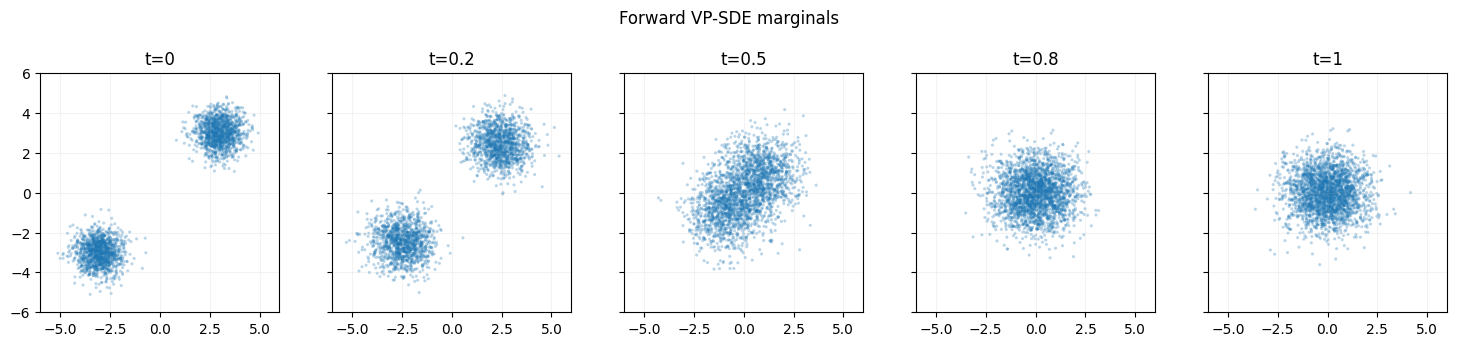

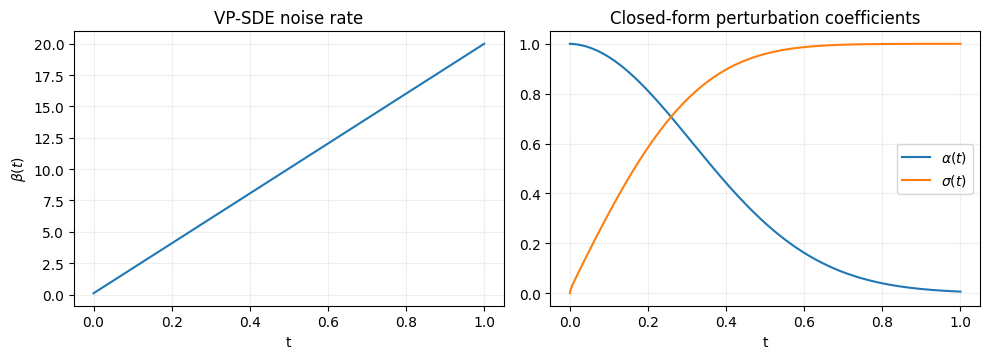

In [4]:
@torch.no_grad()
def plot_forward_marginals():
    x0 = sample_data(N_SAMPLES)
    times_to_show = [0.0, 0.2, 0.5, 0.8, 1.0]
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), sharex=True, sharey=True)
    for ax, t_value in zip(axes, times_to_show):
        if t_value == 0:
            points = x0
        else:
            t = torch.full((N_SAMPLES, 1), t_value, device=DEVICE)
            points, _, _ = perturb(x0, t)
        points = points.cpu().numpy()
        ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
        ax.set_title(f"t={t_value:g}")
        ax.set_xlim(-6, 6)
        ax.set_ylim(-6, 6)
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle("Forward VP-SDE marginals", y=1.04)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "01_forward_vp_sde.png", dpi=160, bbox_inches="tight")
    plt.show()

    t_grid = torch.linspace(0, 1, 500, device=DEVICE)
    alpha, sigma = alpha_sigma(t_grid)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
    axes[0].plot(t_grid.cpu(), beta(t_grid).cpu())
    axes[0].set(xlabel="t", ylabel=r"$\beta(t)$", title="VP-SDE noise rate")
    axes[1].plot(t_grid.cpu(), alpha.cpu(), label=r"$\alpha(t)$")
    axes[1].plot(t_grid.cpu(), sigma.cpu(), label=r"$\sigma(t)$")
    axes[1].set(xlabel="t", title="Closed-form perturbation coefficients")
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "02_vp_sde_schedule.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_forward_marginals()

## 4. 连续时间 Score Network

网络输入 $x_t$ 和连续时间的正弦编码。为提高数值稳定性，前向传播预测加入的噪声 $\hat\epsilon_\theta$，再通过

$$
s_\theta(x_t,t)=-\frac{\hat\epsilon_\theta(x_t,t)}{\sigma(t)}
$$

转换为 Score。这与直接预测 Score 并使用 $\sigma^2(t)$ 加权的 DSM 完全等价。

In [5]:
class ScoreNet(nn.Module):
    def __init__(self, hidden=128, time_dim=32):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM + time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, DIM),
        )

    def time_embedding(self, t):
        if t.ndim == 0:
            t = t.expand(1, 1)
        elif t.ndim == 1:
            t = t[:, None]
        half = self.time_dim // 2
        frequencies = torch.exp(
            torch.linspace(math.log(1.0), math.log(1_000.0), half, device=t.device)
        )
        angles = 2 * math.pi * t * frequencies[None, :]
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return self.net(torch.cat([x / 4.0, self.time_embedding(t)], dim=1))

    def score(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        _, sigma = alpha_sigma(t)
        return -self.forward(x, t) / sigma


model = ScoreNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

ScoreNet(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 37,762


## 5. 连续时间去噪 Score Matching

每个样本独立均匀抽取 $t\sim\mathcal U(\varepsilon,1)$，损失为

$$
\mathbb E\left[\|\hat\epsilon_\theta(x_t,t)-\epsilon\|^2\right]
=\mathbb E\left[\|\sigma(t)s_\theta(x_t,t)+\epsilon\|^2\right].
$$

网络看不到 $x_0$。MSE 的最优解是条件期望，因此它最终学习的是扰动后边缘分布 $p_t(x)$ 的 Score。

In [6]:
losses = []
model.train()
started = time.perf_counter()

for step in range(1, TRAIN_STEPS + 1):
    x0 = sample_data(BATCH_SIZE)
    t = torch.rand(BATCH_SIZE, 1, device=DEVICE) * (1.0-T_EPS) + T_EPS
    xt, noise, _ = perturb(x0, t)
    predicted_noise = model(xt, t)
    loss = (predicted_noise-noise).square().sum(dim=1).mean()

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 600 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(200-step avg)={np.mean(losses[-200:]):.6f}")

print(f"Training finished in {time.perf_counter()-started:.1f} s")
torch.save(model.state_dict(), OUTPUT_DIR / "song_sde_score_model.pt")

step    1/6000 | loss(200-step avg)=1.951166


step  600/6000 | loss(200-step avg)=0.558542


step 1200/6000 | loss(200-step avg)=0.536895


step 1800/6000 | loss(200-step avg)=0.524901


step 2400/6000 | loss(200-step avg)=0.524721


...

step 3600/6000 | loss(200-step avg)=0.521262


step 4200/6000 | loss(200-step avg)=0.522458


step 4800/6000 | loss(200-step avg)=0.524327


step 5400/6000 | loss(200-step avg)=0.520165


step 6000/6000 | loss(200-step avg)=0.520265
Training finished in 16.6 s


## 6. 解析边缘 Score 与网络评估

前向 VP-SDE 将每个原始高斯分量变为

$$
\mathcal N\left(\alpha(t)\mu_i,
[\alpha^2(t)\,0.6^2+\sigma^2(t)]I\right).
$$

因此能解析计算混合分布 Score。它只用于评估和 Oracle 采样，不参与训练。

      t   sigma(t)      score MSE     scaled MSE
  0.010    0.04464       4.140357       0.008252
  0.050    0.17156       0.062814       0.001849
  0.100    0.32205       0.018646       0.001934
  0.300    0.77696       0.011069       0.006682
  0.600    0.98681       0.001279       0.001246
  1.000    0.99998       0.009745       0.009745


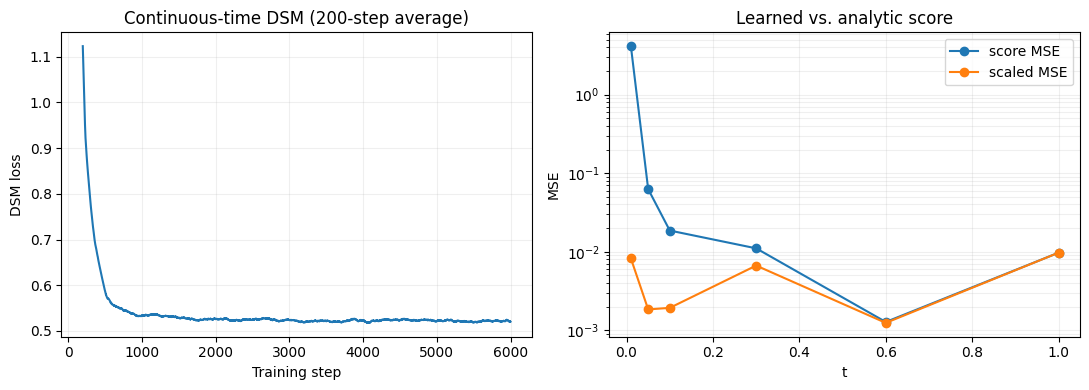

In [7]:
def true_score(x, t):
    if t.ndim == 0:
        t = t.expand(len(x), 1)
    elif t.ndim == 1:
        t = t[:, None]
    alpha, sigma = alpha_sigma(t)
    centers = alpha[:, None, :] * MEANS[None, :, :]
    variance = (alpha.square() * DATA_STD**2 + sigma.square())[:, None, :]
    diff = x[:, None, :] - centers
    logits = torch.log(WEIGHTS)[None, :] - diff.square().sum(-1) / (2 * variance.squeeze(-1))
    responsibilities = torch.softmax(logits, dim=1)
    return (responsibilities[:, :, None] * (-diff / variance)).sum(dim=1)


@torch.no_grad()
def evaluate_score(n=10_000):
    model.eval()
    rows = []
    for t_value in [0.01, 0.05, 0.1, 0.3, 0.6, 1.0]:
        t = torch.full((n, 1), t_value, device=DEVICE)
        xt, _, sigma = perturb(sample_data(n), t)
        pred = model.score(xt, t)
        target = true_score(xt, t)
        mse = (pred-target).square().mean().item()
        scaled_mse = (sigma.square() * (pred-target).square()).mean().item()
        rows.append((t_value, sigma[0].item(), mse, scaled_mse))
    return np.asarray(rows)


score_metrics = evaluate_score()
print(f"{'t':>7} {'sigma(t)':>10} {'score MSE':>14} {'scaled MSE':>14}")
for t_value, sigma, mse, scaled_mse in score_metrics:
    print(f"{t_value:7.3f} {sigma:10.5f} {mse:14.6f} {scaled_mse:14.6f}")

window = 200
loss_smooth = np.convolve(losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses)+1), loss_smooth)
axes[0].set(xlabel="Training step", ylabel="DSM loss", title=f"Continuous-time DSM ({window}-step average)")
axes[0].grid(alpha=0.2)
axes[1].semilogy(score_metrics[:, 0], score_metrics[:, 2], "o-", label="score MSE")
axes[1].semilogy(score_metrics[:, 0], score_metrics[:, 3], "o-", label="scaled MSE")
axes[1].set(xlabel="t", ylabel="MSE", title="Learned vs. analytic score")
axes[1].legend()
axes[1].grid(alpha=0.2, which="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_training_and_score_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Score 向量场

选择 $t=0.2$，此时两个模态仍然清晰，但中间区域已经获得概率质量。解析场和学习场应具有一致的吸引方向与模态分界。

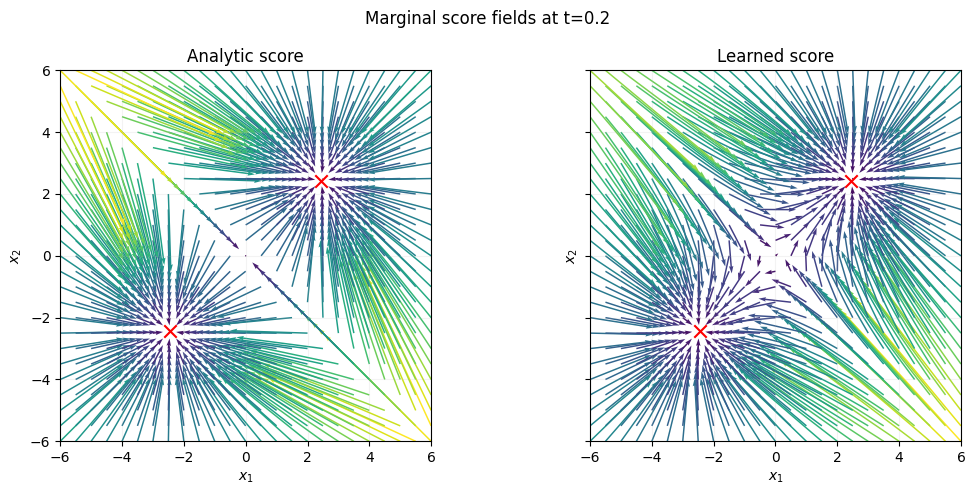

In [8]:
@torch.no_grad()
def plot_score_fields(t_value=0.2):
    axis = torch.linspace(-6, 6, 25, device=DEVICE)
    yy, xx = torch.meshgrid(axis, axis, indexing="ij")
    points = torch.stack([xx.ravel(), yy.ravel()], dim=1)
    t = torch.full((len(points), 1), t_value, device=DEVICE)
    fields = [true_score(points, t), model.score(points, t)]
    titles = ["Analytic score", "Learned score"]
    p = points.cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    for ax, field, title in zip(axes, fields, titles):
        f = field.cpu().numpy()
        magnitude = np.linalg.norm(f, axis=1)
        ax.quiver(p[:, 0], p[:, 1], f[:, 0], f[:, 1], magnitude,
                  cmap="viridis", angles="xy", scale_units="xy", scale=3.0, width=0.004)
        current_means = (alpha_sigma(torch.tensor(t_value, device=DEVICE))[0] * MEANS).cpu().numpy()
        ax.scatter(current_means[:, 0], current_means[:, 1], c="red", marker="x", s=80)
        ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-6, 6), ylim=(-6, 6))
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle(f"Marginal score fields at t={t_value}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "04_score_fields.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_score_fields()

## 8. 三种连续时间采样器

对于前向 SDE $dx=f(x,t)dt+g(t)dW_t$，反向时间 SDE 为

$$
dx=[f(x,t)-g^2(t)\nabla_x\log p_t(x)]dt+g(t)d\bar W_t,
$$

其中时间从 1 积分到 $\varepsilon$。Probability Flow ODE 为

$$
dx=[f(x,t)-\tfrac12g^2(t)\nabla_x\log p_t(x)]dt.
$$

两者在 Score 精确且连续求解精确时具有相同的边缘分布，但路径不相同。Predictor-Corrector 在反向 SDE 的 Euler 预测后增加一次 Langevin 校正。

In [9]:
@torch.no_grad()
def sample(method, score_fn, initial_noise, steps=SAMPLE_STEPS, corrector_steps=1, snr=0.12):
    x = initial_noise.clone()
    times = torch.linspace(1.0, T_EPS, steps+1, device=DEVICE)
    snapshots = {0: x.cpu().numpy().copy()}

    for i in range(steps):
        t, t_next = times[i], times[i+1]
        h = t-t_next
        b = beta(t)
        score = score_fn(x, t)

        if method == "ode":
            x = x + 0.5 * b * (x+score) * h
        else:
            x = x + (0.5*b*x+b*score)*h + torch.sqrt(b*h)*torch.randn_like(x)
            if method == "pc":
                for _ in range(corrector_steps):
                    grad = score_fn(x, t_next)
                    noise = torch.randn_like(x)
                    grad_norm = torch.linalg.vector_norm(grad, dim=-1).mean().clamp_min(1e-8)
                    noise_norm = torch.linalg.vector_norm(noise, dim=-1).mean()
                    step_size = 2 * (snr*noise_norm/grad_norm).square()
                    step_size = step_size.clamp(max=0.02)
                    x = x + step_size*grad + torch.sqrt(2*step_size)*noise

        if i+1 in {steps//4, steps//2, 3*steps//4, steps}:
            snapshots[i+1] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots


initial_noise = torch.randn(N_SAMPLES, DIM, device=DEVICE)
sampling_started = time.perf_counter()
learned_sde, sde_stages = sample("sde", model.score, initial_noise)
learned_ode, ode_stages = sample("ode", model.score, initial_noise)
learned_pc, pc_stages = sample("pc", model.score, initial_noise)
oracle_sde, _ = sample("sde", true_score, initial_noise)
oracle_ode, _ = sample("ode", true_score, initial_noise)
print(f"Five samplers finished in {time.perf_counter()-sampling_started:.1f} s")

Five samplers finished in 2.5 s


## 9. 采样结果对照

学习采样器检验网络与求解器的组合效果；Oracle 采样器直接使用解析 Score，用来单独检验离散求解器。若 Oracle 正确而学习采样偏离目标，主要问题来自 Score 网络；若两者都偏离，则应检查离散步数和更新公式。

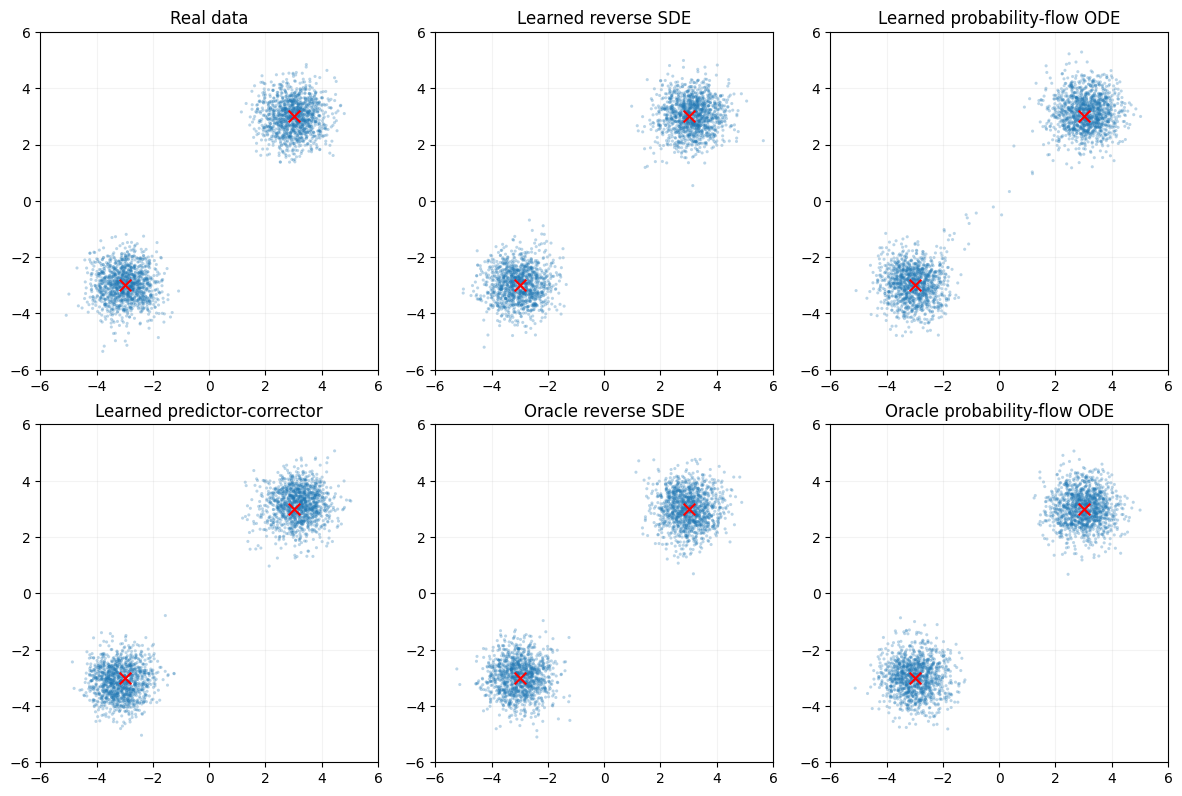

sampler                         weights            mean error   avg std


Real data                       [0.498 0.502]          0.0212    0.6008
Learned reverse SDE             [0.484 0.516]          0.0800    0.6078
Learned probability-flow ODE    [0.48 0.52]            0.1040    0.6263
Learned predictor-corrector     [0.492 0.508]          0.2060    0.5892
Oracle reverse SDE              [0.491 0.509]          0.0203    0.6033
Oracle probability-flow ODE     [0.484 0.516]          0.0157    0.6057


In [10]:
def scatter(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.scatter(MEANS[:, 0].cpu(), MEANS[:, 1].cpu(), c="red", marker="x", s=70)
    ax.set_title(title)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)


with torch.no_grad():
    real = sample_data(N_SAMPLES).cpu().numpy()

names = ["Real data", "Learned reverse SDE", "Learned probability-flow ODE",
         "Learned predictor-corrector", "Oracle reverse SDE", "Oracle probability-flow ODE"]
arrays = [real, learned_sde, learned_ode, learned_pc, oracle_sde, oracle_ode]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, points, title in zip(axes.flat, arrays, names):
    scatter(ax, points, title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_sampler_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


def distribution_summary(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    labels = torch.cdist(points_t, MEANS).argmin(dim=1)
    weights = torch.bincount(labels, minlength=2).float()/len(points_t)
    means = torch.stack([points_t[labels == i].mean(0) for i in range(2)])
    stds = torch.stack([points_t[labels == i].std(0) for i in range(2)])
    return weights.cpu().numpy(), means.cpu().numpy(), stds.cpu().numpy()


print(f"{'sampler':<31} {'weights':<17} {'mean error':>11} {'avg std':>9}")
summaries = {}
for name, points in zip(names, arrays):
    weights, means, stds = distribution_summary(points)
    mean_error = np.linalg.norm(means-MEANS.cpu().numpy(), axis=1).mean()
    summaries[name] = (weights, means, stds)
    print(f"{name:<31} {str(np.round(weights,3)):<17} {mean_error:11.4f} {stds.mean():9.4f}")

## 10. 反向生成轨迹

下面使用相同的初始 $x_1$ 对比随机的反向 SDE 与确定性的 Probability Flow ODE。图中比较的是群体边缘分布；即使最终分布相同，两种方法也不会逐样本对应。

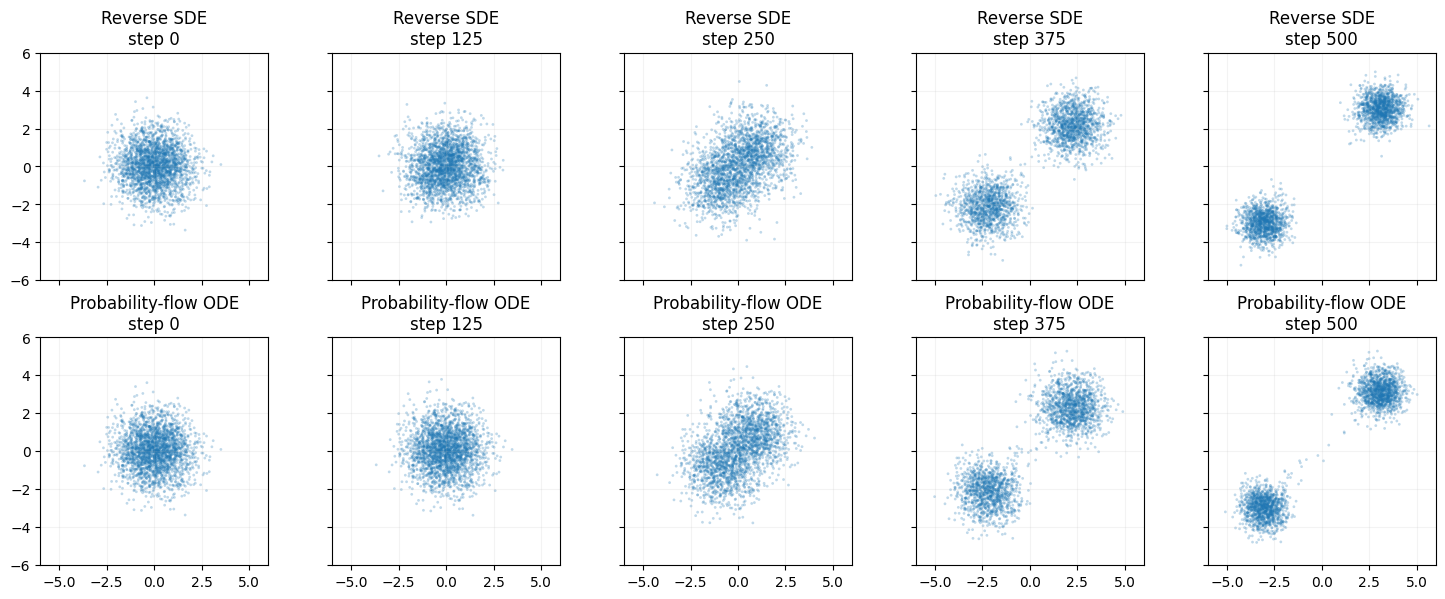

In [11]:
stage_ids = [0, SAMPLE_STEPS//4, SAMPLE_STEPS//2, 3*SAMPLE_STEPS//4, SAMPLE_STEPS]
fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharex=True, sharey=True)
for row, (stages, row_name) in enumerate([(sde_stages, "Reverse SDE"), (ode_stages, "Probability-flow ODE")]):
    for col, stage in enumerate(stage_ids):
        points = stages[stage]
        axes[row, col].scatter(points[:, 0], points[:, 1], s=4, alpha=0.28, edgecolors="none")
        axes[row, col].set_title(f"{row_name}\nstep {stage}")
        axes[row, col].set_xlim(-6, 6)
        axes[row, col].set_ylim(-6, 6)
        axes[row, col].set_aspect("equal")
        axes[row, col].grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_reverse_trajectories.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. 公式与代码对应关系

| 代码对象 | 数学对象 | 作用 |
|---|---|---|
| `beta(t)` | $\beta(t)$ | VP-SDE 的连续噪声率 |
| `alpha_sigma(t)` | $\alpha(t),\sigma(t)$ | 闭式扰动核系数 |
| `perturb()` | $p_{0t}(x_t\mid x_0)$ | 一步采样任意连续时间 |
| `ScoreNet.score()` | $s_\theta(x,t)$ | 连续时间边缘 Score |
| DSM 训练循环 | $\mathbb E\|\sigma s_\theta+\epsilon\|^2$ | 学习所有时间的 Score |
| `sample("sde", ...)` | 反向时间 SDE | 随机生成 |
| `sample("ode", ...)` | Probability Flow ODE | 确定性生成 |
| `sample("pc", ...)` | Predictor-Corrector | 预测后用 Langevin 校正 |
| `true_score()` | $\nabla_x\log p_t(x)$ | 解析评估与 Oracle 对照 |

实验成功需要同时满足：终点接近标准高斯、scaled Score MSE 较小、Oracle 采样正确、学习采样恢复两个中心及分量方差。反向 SDE 和概率流 ODE 在理想条件下共享相同边缘分布，这不意味着它们拥有相同样本路径。